# The `rx_angle` Surprise: Why $Z$-Dephasing Noise is Invisible at $\theta = 0$

In a 1D Transverse-Field Ising mirror circuit ($U \cdot U^\dagger$), the ideal noiseless final state is $|00\dots 0\rangle$, meaning $\langle Z_i \rangle = +1.0$ on every qubit.

When we inject hardware-like Pauli-Lindblad noise into the 2-qubit `CZ` boxes, the dominant error generators are **$Z$-type dephasing errors** (`ZZ`, `IZ`, `ZI`, `Z`). How much those errors hurt your final $Z$-basis measurement depends dramatically on `rx_angle` ($\theta$):

$$R_X(\theta)\, Z \, R_X^\dagger(\theta) = \cos(\theta)\, Z + \sin(\theta)\, Y$$

1. **At `rx_angle = 0` ($\sin 0 = 0$):** Every gate in the circuit ($S^\dagger$, $S$, `CZ`) is diagonal in the $Z$-basis and commutes with $Z$ errors. Any `Z`, `IZ`, `ZI`, or `ZZ` phase error slides all the way to the measurement without ever flipping $|0\rangle \to |1\rangle$, making $Z$-dephasing **completely invisible** to the $Z$-measurement!
2. **As `rx_angle` increases toward $\pi/2$ ($\sin(\pi/2) = 1$):** The $R_X(\theta)$ rotations tip the qubits into the $XY$-plane, converting `Z` and `ZZ` phase errors into `Y` **bit-flip errors** and allowing them to spread across neighboring `CZ` gates.


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

from qiskit import QuantumCircuit
from qiskit.circuit import BoxOp, CircuitInstruction, Parameter
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter
from qiskit.quantum_info import Pauli, SparsePauliOp, PauliLindbladMap
from qiskit.transpiler import generate_preset_pass_manager

from qiskit_ibm_runtime import QuantumProgram
from qiskit_ibm_runtime.options import EstimatorOptions
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh

# Samplomatic
import samplomatic
from samplomatic import Twirl, InjectNoise, ChangeBasis, build
from samplomatic.transpiler import generate_boxing_pass_manager
from samplomatic.utils import find_unique_box_instructions, get_annotation

# Local learner and simulator
from qiskit_aer import AerSimulator
from qiskit_noise_learning.aer_executor import AerExecutor
from qiskit_noise_learning.noise_learner import LearningOptions, NoiseLearner

In [12]:
def synthetic_noise_dict(
    unique_layers,
    seed: int = 42,
    mean_rate_1q: float = 2e-3,
    mean_rate_2q: float = 1e-2,
    mean_spam_rate: float = 1e-2,
) -> dict[str, PauliLindbladMap]:
    """Build synthetic Pauli-Lindblad noise maps for local AerExecutor noise learning."""
    rng = np.random.default_rng(seed)
    noise_dict = {}

    # Keep only gate boxes carrying InjectNoise
    unique_layers[:] = [
        inst for inst in unique_layers
        if get_annotation(inst.operation, InjectNoise) is not None
    ]

    # Collect all active physical Qubit objects across all layers in ascending index order
    all_qubits = sorted(
        {q for inst in unique_layers for q in inst.qubits if q._index is not None},
        key=lambda q: q._index,
    )
    all_active_qubits = {q._index for q in all_qubits}

    for idx, inst in enumerate(unique_layers):
        orig_phys = (inst.operation.body.metadata or {}).get(
            "orig_phys_qubits", sorted(q._index for q in inst.qubits)
        )
        if list(inst.qubits) != all_qubits:
            old_body = inst.operation.body
            q_map = [all_qubits.index(q) for q in inst.qubits]
            new_body = QuantumCircuit(len(all_qubits), old_body.num_clbits)
            new_body.compose(
                old_body,
                qubits=q_map,
                clbits=list(range(old_body.num_clbits)),
                inplace=True,
            )
            new_body.metadata = {"orig_phys_qubits": orig_phys}
            new_box = BoxOp(new_body, annotations=inst.operation.annotations)
            inst = CircuitInstruction(new_box, tuple(all_qubits), inst.clbits)
            unique_layers[idx] = inst
        else:
            inst.operation.body.metadata = {"orig_phys_qubits": orig_phys}

        inj_ann = get_annotation(inst.operation, InjectNoise)
        if inj_ann is None:
            continue
        tag_ref = inj_ann.ref
        num_layer_qubits = len(inst.qubits)
        sparse_terms = []

        # 1Q Pauli-Lindblad rates on each local qubit index
        for local_i in range(num_layer_qubits):
            for pauli in ("X", "Y", "Z"):
                r1 = float(rng.uniform(0.5 * mean_rate_1q, 1.5 * mean_rate_1q))
                sparse_terms.append((pauli, [local_i], r1))

        # 2Q Pauli-Lindblad rates on each 2Q gate inside the box body (dominated by ZZ, IZ, ZI)
        box_circuit = inst.operation.body
        for sub_inst in box_circuit.data:
            if len(sub_inst.qubits) == 2:
                l0 = box_circuit.find_bit(sub_inst.qubits[0]).index
                l1 = box_circuit.find_bit(sub_inst.qubits[1]).index
                for pauli_2q, scale in [("ZZ", 1.0), ("XX", 0.5), ("YY", 0.5), ("IZ", 0.5), ("ZI", 0.5)]:
                    r2 = float(rng.uniform(0.5 * mean_rate_2q, 1.5 * mean_rate_2q) * scale)
                    sparse_terms.append((pauli_2q, [l0, l1], r2))

        noise_dict[tag_ref] = PauliLindbladMap.from_sparse_list(
            sparse_terms, num_qubits=num_layer_qubits
        )

    # SPAM noise for AerExecutor's active learning qubits
    num_active = len(all_active_qubits)
    if num_active > 0:
        p_terms = [("X", [i], float(rng.uniform(0.5 * mean_spam_rate, 1.5 * mean_spam_rate))) for i in range(num_active)]
        m_terms = [("X", [i], float(rng.uniform(0.5 * mean_spam_rate, 1.5 * mean_spam_rate))) for i in range(num_active)]
        noise_dict["P"] = PauliLindbladMap.from_sparse_list(p_terms, num_qubits=num_active)
        noise_dict["M"] = PauliLindbladMap.from_sparse_list(m_terms, num_qubits=num_active)

    return noise_dict

In [13]:
def local_result_to_dict(noise_result, unique_layers):
    """
    Local equivalent of NoiseLearnerV3Results.to_dict(unique_layers, unique_refs=False).
    Slices the 156-qubit global PauliLindbladMap down to the exact local qubits of each box.
    """
    global_noise_dict = noise_result.to_dict()
    refs_to_noise = {}

    for inst in unique_layers:
        inj_ann = get_annotation(inst.operation, InjectNoise)
        if inj_ann is None:
            continue
        ref = inj_ann.ref
        if ref in global_noise_dict:
            global_map = global_noise_dict[ref]
            box_body = inst.operation.body
            orig_phys = (box_body.metadata or {}).get("orig_phys_qubits")
            if orig_phys is not None:
                phys_qubits = orig_phys
            else:
                phys_qubits = sorted(q._index for q in inst.qubits)

            if global_map.num_qubits > len(phys_qubits):
                refs_to_noise[ref] = global_map.keep_qubits(phys_qubits)
            else:
                refs_to_noise[ref] = global_map

    return refs_to_noise

In [14]:
def construct_ising_circuit(
    num_qubits: int,
    num_trotter_steps: int,
    rx_angle: float | Parameter,
    barrier: bool = True,
) -> QuantumCircuit:
    """Construct a Trotterized 1D Transverse-Field Ising circuit using Sdg + CZ blocks."""
    qc = QuantumCircuit(num_qubits)
    for _ in range(num_trotter_steps):
        qc.rx(rx_angle, range(num_qubits))
        if barrier:
            qc.barrier()
        for first_qubit in (1, 2):
            for idx in range(first_qubit, num_qubits, 2):
                qc.sdg([idx - 1, idx])
                qc.cz(idx - 1, idx)
        if barrier:
            qc.barrier()
    return qc

## Part 1: Qiskit's Built-in Library (`PauliEvolutionGate` + `LieTrotter`) vs. `construct_ising_circuit`

Qiskit provides `SparsePauliOp`, `PauliEvolutionGate`, and `LieTrotter` in `qiskit.circuit.library` / `qiskit.synthesis` to automatically build Trotterized evolution circuits directly from the Hamiltonian:
$$H = -J \sum_{\langle i, j \rangle} Z_i Z_j + h \sum_i X_i$$
Below, we compare Qiskit's built-in `LieTrotter` synthesis (which emits `RX` and `RZZ` gates) with `construct_ising_circuit` (which rewrites each `RZZ(-π/2)` as `S†` + `CZ` so every 2-qubit gate is a single Clifford `CZ` gate).

Qiskit built-in PauliEvolutionGate + LieTrotter (1 Trotter step):


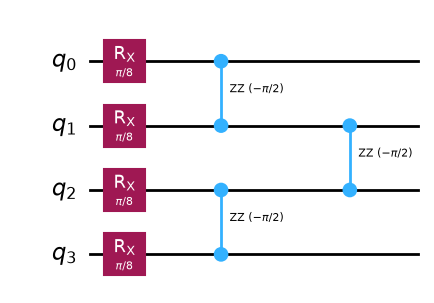

In [15]:
def build_qiskit_builtin_ising(
    num_qubits: int,
    num_trotter_steps: int,
    rx_angle: float | Parameter,
) -> QuantumCircuit:
    """Build the 1D Ising Trotter circuit using Qiskit's PauliEvolutionGate + LieTrotter."""
    x_terms = [("X", [i], rx_angle / 2) for i in range(num_qubits)]
    zz_even = [("ZZ", [i - 1, i], -np.pi / 4) for i in range(1, num_qubits, 2)]
    zz_odd  = [("ZZ", [i - 1, i], -np.pi / 4) for i in range(2, num_qubits, 2)]

    hamiltonian = SparsePauliOp.from_sparse_list(
        x_terms + zz_even + zz_odd,
        num_qubits=num_qubits,
    )
    evo_gate = PauliEvolutionGate(
        hamiltonian,
        time=1.0,
        synthesis=LieTrotter(reps=num_trotter_steps),
    )
    qc = QuantumCircuit(num_qubits)
    qc.append(evo_gate, range(num_qubits))
    return qc.decompose()


qc_builtin = build_qiskit_builtin_ising(num_qubits=4, num_trotter_steps=1, rx_angle=np.pi / 8)
print("Qiskit built-in PauliEvolutionGate + LieTrotter (1 Trotter step):")
display(qc_builtin.draw("mpl", fold=-1))

## Part 2: Setup Backend, Boxing Pass Manager, and Learn Layer Noise Locally

In [16]:
backend = FakeMarrakesh()
print(f"Backend: {backend.backend_name}")
print(f"Qubits: {backend.num_qubits}")
print(f"Basis gates: {backend.basis_gates}")

isa_pm = generate_preset_pass_manager(backend=backend, optimization_level=0)

noise_learning_boxing_pm = generate_boxing_pass_manager(
    enable_gates=True,
    enable_measures=True,
    twirling_strategy="active",
    inject_noise_targets="gates",
    inject_noise_strategy="no_modification",
)

Backend: fake_marrakesh
Qubits: 156
Basis gates: ['cz', 'id', 'rz', 'sx', 'x']


In [17]:
num_qubits = 4
num_trotter_steps = 2

ising_ex2 = construct_ising_circuit(
    num_qubits=num_qubits,
    num_trotter_steps=num_trotter_steps,
    rx_angle=np.pi / 8,
    barrier=False,
)

mirror_ex2 = QuantumCircuit(num_qubits)
mirror_ex2.compose(ising_ex2, inplace=True)
mirror_ex2.barrier()
mirror_ex2.compose(ising_ex2.inverse(), inplace=True)
mirror_ex2.measure_all()

mirror_ex2_isa = isa_pm.run(mirror_ex2)
boxed_circuit_ex2 = noise_learning_boxing_pm.run(mirror_ex2_isa)

unique_layers_ex3 = find_unique_box_instructions(
    boxed_circuit_ex2,
    normalize_annotations=None,
    undress_boxes=True,
)

toy_noise_dict_ex3 = synthetic_noise_dict(unique_layers_ex3)

nl_options_ex3 = LearningOptions(
    num_randomizations=8,
    shots_per_randomization=32,
    fragment_depths=[1, 2, 4],
)

aer_executor_ex3 = AerExecutor(
    AerSimulator(),
    noise_dict=toy_noise_dict_ex3,
    warn_absent=False,
    #root_seed=2026,
)

learner_ex3 = NoiseLearner(
    backend,
    options=nl_options_ex3,
    executor=aer_executor_ex3,
)

learner_job_ex3 = learner_ex3.run(unique_layers_ex3)
toy_noise_result_ex3 = learner_job_ex3.result()
refs_to_noise_models_ex3 = local_result_to_dict(toy_noise_result_ex3, unique_layers_ex3)

print(f"Learned noise for {len(refs_to_noise_models_ex3)} unique layers: {list(refs_to_noise_models_ex3.keys())}")
for ref, plm in refs_to_noise_models_ex3.items():
    print(f"  Layer '{ref}': {plm.num_qubits}-qubit PauliLindbladMap")

Learned noise for 2 unique layers: ['ra79A', 'r45aA']
  Layer 'ra79A': 4-qubit PauliLindbladMap
  Layer 'r45aA': 2-qubit PauliLindbladMap


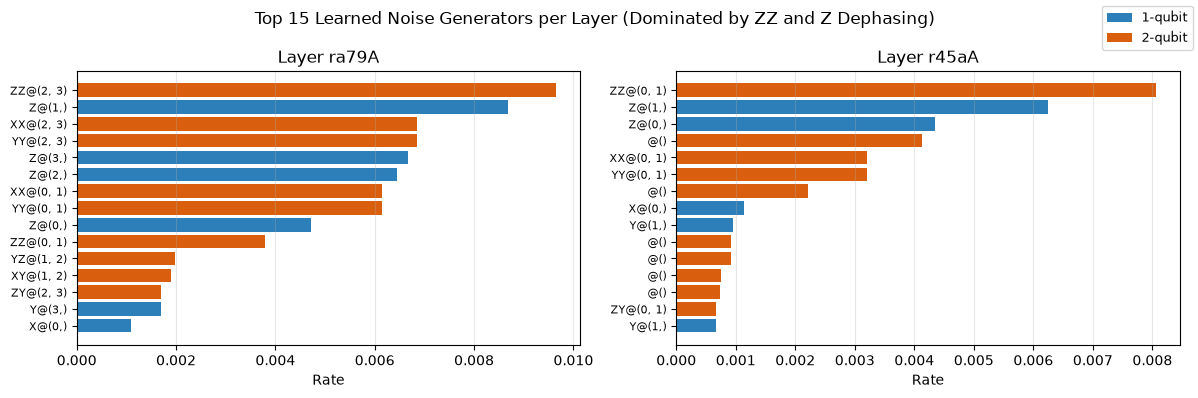

In [18]:
# Plot the top 15 learned noise generators per layer
fig, axes = plt.subplots(1, len(refs_to_noise_models_ex3), figsize=(12, 4))
if len(refs_to_noise_models_ex3) == 1:
    axes = [axes]

for ax, (ref, plm) in zip(axes, refs_to_noise_models_ex3.items()):
    gens = sorted(plm.to_sparse_list(), key=lambda g: -abs(g[2]))[:15]
    labels = [f"{p}@{tuple(q)}" for p, q, _ in gens]
    rates = [r for _, _, r in gens]
    colors = ["#2c7fb8" if len(p) == 1 else "#d95f0e" for p, _, _ in gens]
    ax.barh(range(len(labels)), rates, color=colors)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("Rate")
    ax.set_title(f"Layer {ref}")
    ax.grid(axis="x", alpha=0.3)

fig.legend(
    handles=[
        Patch(facecolor="#2c7fb8", label="1-qubit"),
        Patch(facecolor="#d95f0e", label="2-qubit"),
    ],
    loc="upper right",
    fontsize=9,
)
fig.suptitle("Top 15 Learned Noise Generators per Layer (Dominated by ZZ and Z Dephasing)")
plt.tight_layout()
plt.show()

## Part 3: The `rx_angle` Surprise — Sweeping `rx_angle` from $0$ to $\pi/2$

Using Qiskit's symbolic `Parameter("rx_angle")` and Samplomatic's broadcastable `parameter_values`, we build a **single** parameterized template circuit and evaluate 5 values of `rx_angle` ($0, \pi/8, \pi/4, 3\pi/8, \pi/2$) in one `QuantumProgram` using the exact same learned noise models `refs_to_noise_models_ex3`.

In [19]:
# 1. Build a single parameterized Ising mirror circuit using Qiskit's Parameter
theta = Parameter("rx_angle")

ising_param = construct_ising_circuit(
    num_qubits=num_qubits,
    num_trotter_steps=num_trotter_steps,
    rx_angle=theta,
    barrier=False,
)

mirror_param = QuantumCircuit(num_qubits)
mirror_param.compose(ising_param, inplace=True)
mirror_param.barrier()
mirror_param.compose(ising_param.inverse(), inplace=True)
mirror_param.measure_all()

# 2. Transpile, box, and build template + samplex once
mirror_param_isa = isa_pm.run(mirror_param)
boxed_param = noise_learning_boxing_pm.run(mirror_param_isa)
template_param, samplex_param = build(boxed_param)

print("Samplex inputs with symbolic Parameter:")
print(samplex_param.inputs())

# 3. Sweep rx_angle across [0, π/8, π/4, 3π/8, π/2]
#    parameter_values has intrinsic shape (1,) and extrinsic broadcast shape (5, 1) -> total shape (5, 1, 1)
angles = np.array([0.0, np.pi / 8, np.pi / 4, 3 * np.pi / 8, np.pi / 2])
angle_labels = ["0", "π/8", "π/4", "3π/8", "π/2"]
num_randomizations = 32

samplex_args_sweep = (
    samplex_param.inputs()
    .make_broadcastable()
    .bind(
        parameter_values=angles[:, None, None],
        pauli_lindblad_maps=refs_to_noise_models_ex3,
    )
)

program_sweep = QuantumProgram(shots=64)
program_sweep.append_samplex_item(
    circuit=template_param,
    samplex=samplex_param,
    samplex_arguments=samplex_args_sweep,
    shape=(len(angles), num_randomizations),
)

# 4. Execute all 5 angles in a single local AerExecutor call
sweep_result = aer_executor_ex3.run(program_sweep).result()[0]
meas_sweep = sweep_result["meas"]                    # shape: (5, 32, 64, 4)
flips_sweep = sweep_result["measurement_flips.meas"] # shape: (5, 32, 1, 4)

corrected_sweep = np.bitwise_xor(meas_sweep, flips_sweep)
z_vals_sweep = 1 - 2 * corrected_sweep.astype(np.int8)

# Average over randomizations (axis 1) and shots (axis 2) -> shape (5 angles, 4 qubits)
z_per_qubit = z_vals_sweep.mean(axis=(1, 2))
z_mean_all = z_per_qubit.mean(axis=1)

print("\nSweep Results:")
for lbl, z_m, z_q in zip(angle_labels, z_mean_all, z_per_qubit):
    print(f"  rx_angle = {lbl:<5} | mean ⟨Z⟩ = {z_m:+.4f} | per-qubit ⟨Z⟩ = {np.round(z_q, 4)}")

Samplex inputs with symbolic Parameter:
TensorInterface(<
  - 'parameter_values' <float64[1]>: Input parameter values to use during sampling.
  - 'pauli_lindblad_maps.r45aA' <PauliLindbladMap>: A PauliLindblad map acting on 2 qubits,
      with 'num_terms_r45aA' terms.
  - 'pauli_lindblad_maps.ra79A' <PauliLindbladMap>: A PauliLindblad map acting on 4 qubits,
      with 'num_terms_ra79A' terms.
>)

Sweep Results:
  rx_angle = 0     | mean ⟨Z⟩ = +0.7812 | per-qubit ⟨Z⟩ = [0.8125 0.6875 0.75   0.875 ]
  rx_angle = π/8   | mean ⟨Z⟩ = +0.8989 | per-qubit ⟨Z⟩ = [0.916  0.8369 0.8789 0.9639]
  rx_angle = π/4   | mean ⟨Z⟩ = +0.7056 | per-qubit ⟨Z⟩ = [0.75   0.7324 0.6348 0.7051]
  rx_angle = 3π/8  | mean ⟨Z⟩ = +0.7551 | per-qubit ⟨Z⟩ = [0.8848 0.7578 0.7021 0.6758]
  rx_angle = π/2   | mean ⟨Z⟩ = +0.6094 | per-qubit ⟨Z⟩ = [0.6875 0.6875 0.3125 0.75  ]


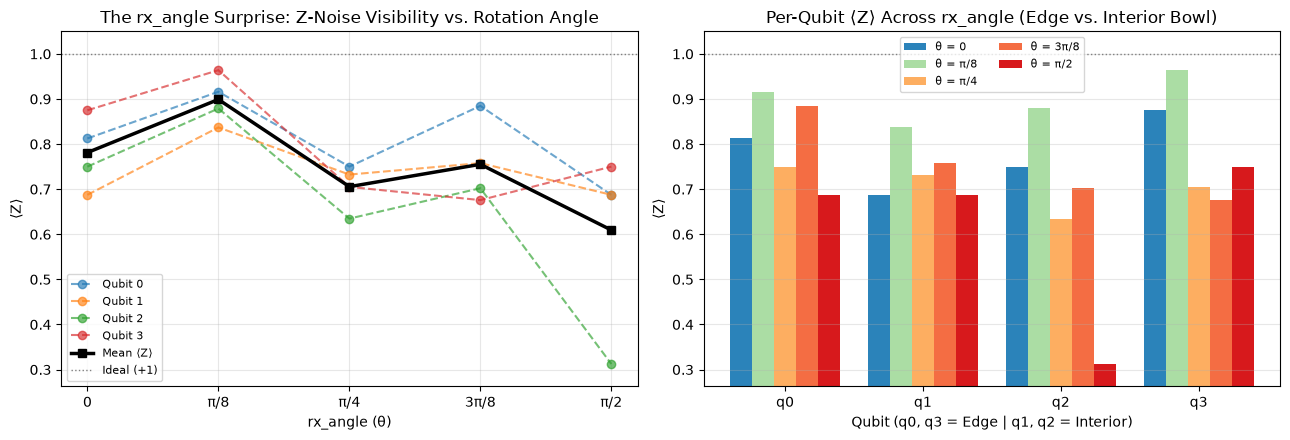

In [20]:
# 5. Visualize the rx_angle Surprise: Overall Decay Curve + Per-Qubit Bowl Profile
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Left panel: <Z> vs rx_angle
for q in range(num_qubits):
    ax1.plot(angles, z_per_qubit[:, q], marker="o", ls="--", alpha=0.65, label=f"Qubit {q}")
ax1.plot(angles, z_mean_all, marker="s", color="black", lw=2.5, label="Mean ⟨Z⟩")
ax1.axhline(1.0, color="gray", ls=":", lw=1, label="Ideal (+1)")
ax1.set_xticks(angles)
ax1.set_xticklabels(angle_labels)
ax1.set_xlabel("rx_angle (θ)")
ax1.set_ylabel("⟨Z⟩")
ax1.set_ylim(min(0.4, float(z_per_qubit.min()) - 0.05), 1.05)
ax1.set_title("The rx_angle Surprise: Z-Noise Visibility vs. Rotation Angle")
ax1.grid(alpha=0.3)
ax1.legend(fontsize=8)

# Right panel: Grouped bar chart per qubit across angles
x = np.arange(num_qubits)
width = 0.16
colors = ["#2b83ba", "#abdda4", "#fdae61", "#f46d43", "#d7191c"]
for i, (lbl, col) in enumerate(zip(angle_labels, colors)):
    offset = (i - len(angles) / 2 + 0.5) * width
    ax2.bar(x + offset, z_per_qubit[i], width=width, color=col, label=f"θ = {lbl}")

ax2.axhline(1.0, color="gray", ls=":", lw=1)
ax2.set_xticks(x)
ax2.set_xticklabels([f"q{q}" for q in range(num_qubits)])
ax2.set_xlabel("Qubit (q0, q3 = Edge | q1, q2 = Interior)")
ax2.set_ylabel("⟨Z⟩")
ax2.set_ylim(min(0.4, float(z_per_qubit.min()) - 0.05), 1.05)
ax2.set_title("Per-Qubit ⟨Z⟩ Across rx_angle (Edge vs. Interior Bowl)")
ax2.grid(axis="y", alpha=0.3)
ax2.legend(fontsize=8, ncol=2)

plt.tight_layout()
plt.show()